<a href="https://colab.research.google.com/github/CristianPacheco92/sentiment-analysis-transformers/blob/main/notebooks/sentiment_analysis_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Cell 1: Environment verification and repository setup
import torch
import os

# Check GPU availability
gpu_available = torch.cuda.is_available()
print(f"CUDA Available: {gpu_available}")

if gpu_available:
    device_name = torch.cuda.get_device_name(0)
    print(f"Active GPU Device: {device_name}")
else:
    print("WARNING: GPU not detected. Ensure T4 GPU is selected in Runtime settings.")

# Clone repository if running in Colab virtual machine
repo_name = "sentiment-analysis-transformers"
if not os.path.exists(repo_name):
    !git clone https://github.com/CristianPacheco92/sentiment-analysis-transformers.git
    %cd sentiment-analysis-transformers
else:
    %cd sentiment-analysis-transformers
    !git pull

print("Working directory initialized successfully.")

CUDA Available: True
Active GPU Device: Tesla T4
Cloning into 'sentiment-analysis-transformers'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 17 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 4.78 KiB | 4.78 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/sentiment-analysis-transformers
Working directory initialized successfully.


In [3]:
# Cell 2: Dataset ingestion and inspection (IMDb benchmark)
from datasets import load_dataset
import pandas as pd

print("Downloading IMDb dataset from Hugging Face repository...")
dataset = load_dataset("stanfordnlp/imdb")

# Convert raw splits to pandas DataFrames for structured inspection
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

# Inspect dataset shapes and class distributions
print("\n--- Dataset Overview ---")
print(f"Training samples: {len(train_df):,}")
print(f"Testing samples:  {len(test_df):,}")

print("\nClass balance (Train):")
print(train_df["label"].value_counts(normalize=True))

print("\nClass balance (Test):")
print(test_df["label"].value_counts(normalize=True))

# Display the first sample text and assigned label
sample_text = train_df["text"].iloc[0]
sample_label = "Positive (1)" if train_df["label"].iloc[0] == 1 else "Negative (0)"
print(f"\nSample review preview:\n{sample_text[:300]}...")
print(f"Assigned label: {sample_label}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]


--- Dataset Overview ---
Training samples: 25,000
Testing samples:  25,000

Class balance (Train):
label
0    0.5
1    0.5
Name: proportion, dtype: float64

Class balance (Test):
label
0    0.5
1    0.5
Name: proportion, dtype: float64

Sample review preview:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h...
Assigned label: Negative (0)


In [4]:
# Cell 3: Text vectorization via TF-IDF (unigrams and bigrams)
from sklearn.feature_extraction.text import TfidfVectorizer

print("Fitting TF-IDF vectorizer on training text...")

# Configure vectorizer: unigrams + bigrams, top 20,000 features, strip accents
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    sublinear_tf=True,
    stop_words="english"
)

# Transform text to numerical feature matrices
X_train = vectorizer.fit_transform(train_df["text"])
y_train = train_df["label"].values

X_test = vectorizer.transform(test_df["text"])
y_test = test_df["label"].values

print(f"TF-IDF feature extraction complete.")
print(f"Train matrix shape: {X_train.shape}")
print(f"Test matrix shape:  {X_test.shape}")

Fitting TF-IDF vectorizer on training text...
TF-IDF feature extraction complete.
Train matrix shape: (25000, 20000)
Test matrix shape:  (25000, 20000)


In [5]:
# Cell 4: Train and evaluate classical baselines (Naive Bayes & Linear SVM)
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
import time

# Dictionary to collect benchmark results for the final comparative table
benchmark_results = {}

# 1. Multinomial Naive Bayes Baseline
print("Training Multinomial Naive Bayes classifier...")
start_time = time.time()
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_train_time = time.time() - start_time

nb_preds = nb_model.predict(X_test)
nb_acc = accuracy_score(y_test, nb_preds)
nb_p, nb_r, nb_f1, _ = precision_recall_fscore_support(y_test, nb_preds, average="binary")

benchmark_results["Multinomial NB"] = {
    "Accuracy": round(nb_acc * 100, 2),
    "Precision": round(nb_p * 100, 2),
    "Recall": round(nb_r * 100, 2),
    "F1-Score": round(nb_f1 * 100, 2),
    "Training Time (s)": round(nb_train_time, 2)
}

print(f"Naive Bayes completed in {nb_train_time:.2f}s | Accuracy: {nb_acc * 100:.2f}% | F1: {nb_f1 * 100:.2f}%")

# 2. Linear Support Vector Machine (LinearSVC) Baseline
print("\nTraining Linear Support Vector Machine (LinearSVC)...")
start_time = time.time()
svm_model = LinearSVC(max_iter=2000, random_state=42)
svm_model.fit(X_train, y_train)
svm_train_time = time.time() - start_time

svm_preds = svm_model.predict(X_test)
svm_acc = accuracy_score(y_test, svm_preds)
svm_p, svm_r, svm_f1, _ = precision_recall_fscore_support(y_test, svm_preds, average="binary")

benchmark_results["Linear SVM"] = {
    "Accuracy": round(svm_acc * 100, 2),
    "Precision": round(svm_p * 100, 2),
    "Recall": round(svm_r * 100, 2),
    "F1-Score": round(svm_f1 * 100, 2),
    "Training Time (s)": round(svm_train_time, 2)
}

print(f"Linear SVM completed in {svm_train_time:.2f}s | Accuracy: {svm_acc * 100:.2f}% | F1: {svm_f1 * 100:.2f}%")

# Tabulate baseline results
import pandas as pd
baseline_df = pd.DataFrame(benchmark_results).T
print("\n=== Baseline Benchmark Comparison ===")
print(baseline_df)

Training Multinomial Naive Bayes classifier...
Naive Bayes completed in 0.02s | Accuracy: 85.66% | F1: 85.43%

Training Linear Support Vector Machine (LinearSVC)...
Linear SVM completed in 0.53s | Accuracy: 87.44% | F1: 87.37%

=== Baseline Benchmark Comparison ===
                Accuracy  Precision  Recall  F1-Score  Training Time (s)
Multinomial NB     85.66      86.81   84.09     85.43               0.02
Linear SVM         87.44      87.89   86.85     87.37               0.53


In [6]:
# Cell 5: Tokenization pipeline using DistilBERT WordPiece tokenizer
from transformers import AutoTokenizer

model_checkpoint = "distilbert-base-uncased"
print(f"Loading tokenizer: {model_checkpoint}...")
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=256
    )

print("Tokenizing training and test splits...")
tokenized_train = dataset["train"].map(tokenize_function, batched=True, batch_size=1000)
tokenized_test = dataset["test"].map(tokenize_function, batched=True, batch_size=1000)

print(f"Tokenization complete. Features: {tokenized_train.column_names}")

Loading tokenizer: distilbert-base-uncased...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizing training and test splits...


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Tokenization complete. Features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


In [7]:
# Cell 6: Hardware check and Hugging Face training prerequisites
import torch

print("Checking runtime acceleration...")
cuda_ready = torch.cuda.is_available()

if cuda_ready:
    print(f"GPU detected: {torch.cuda.get_device_name(0)}. Ready to train DistilBERT.")
else:
    print("STILL ON CPU: You must connect to a GPU runtime before launching the training loop.")

Checking runtime acceleration...
GPU detected: Tesla T4. Ready to train DistilBERT.


In [8]:
# Cell 7: Fine-tuning DistilBERT using Hugging Face Trainer
!pip install -q evaluate accelerate

import numpy as np
import evaluate
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

# Load pretrained DistilBERT with a 2-class classification head
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

# Load metrics via evaluate library
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    f1 = f1_metric.compute(predictions=predictions, references=labels)["f1"]
    return {
        "accuracy": round(acc * 100, 2),
        "f1": round(f1 * 100, 2)
    }

# Define training hyperparameters
training_args = TrainingArguments(
    output_dir="./results_distilbert",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    fp16=True,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none"
)

# Initialize Trainer instance
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics,
)

print("Starting DistilBERT fine-tuning...")
train_result = trainer.train()

print("\nEvaluating on full test split...")
eval_results = trainer.evaluate()

print("\n=== DistilBERT Test Performance ===")
for metric_name, score in eval_results.items():
    print(f"{metric_name}: {score}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.5 MB/s eta 0:00:00


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Evaluating on full test split...


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.144776,0.270544,2,91.150000,91.220000



=== DistilBERT Test Performance ===
eval_loss: 0.2705441117286682
eval_accuracy: 91.15
eval_f1: 91.22


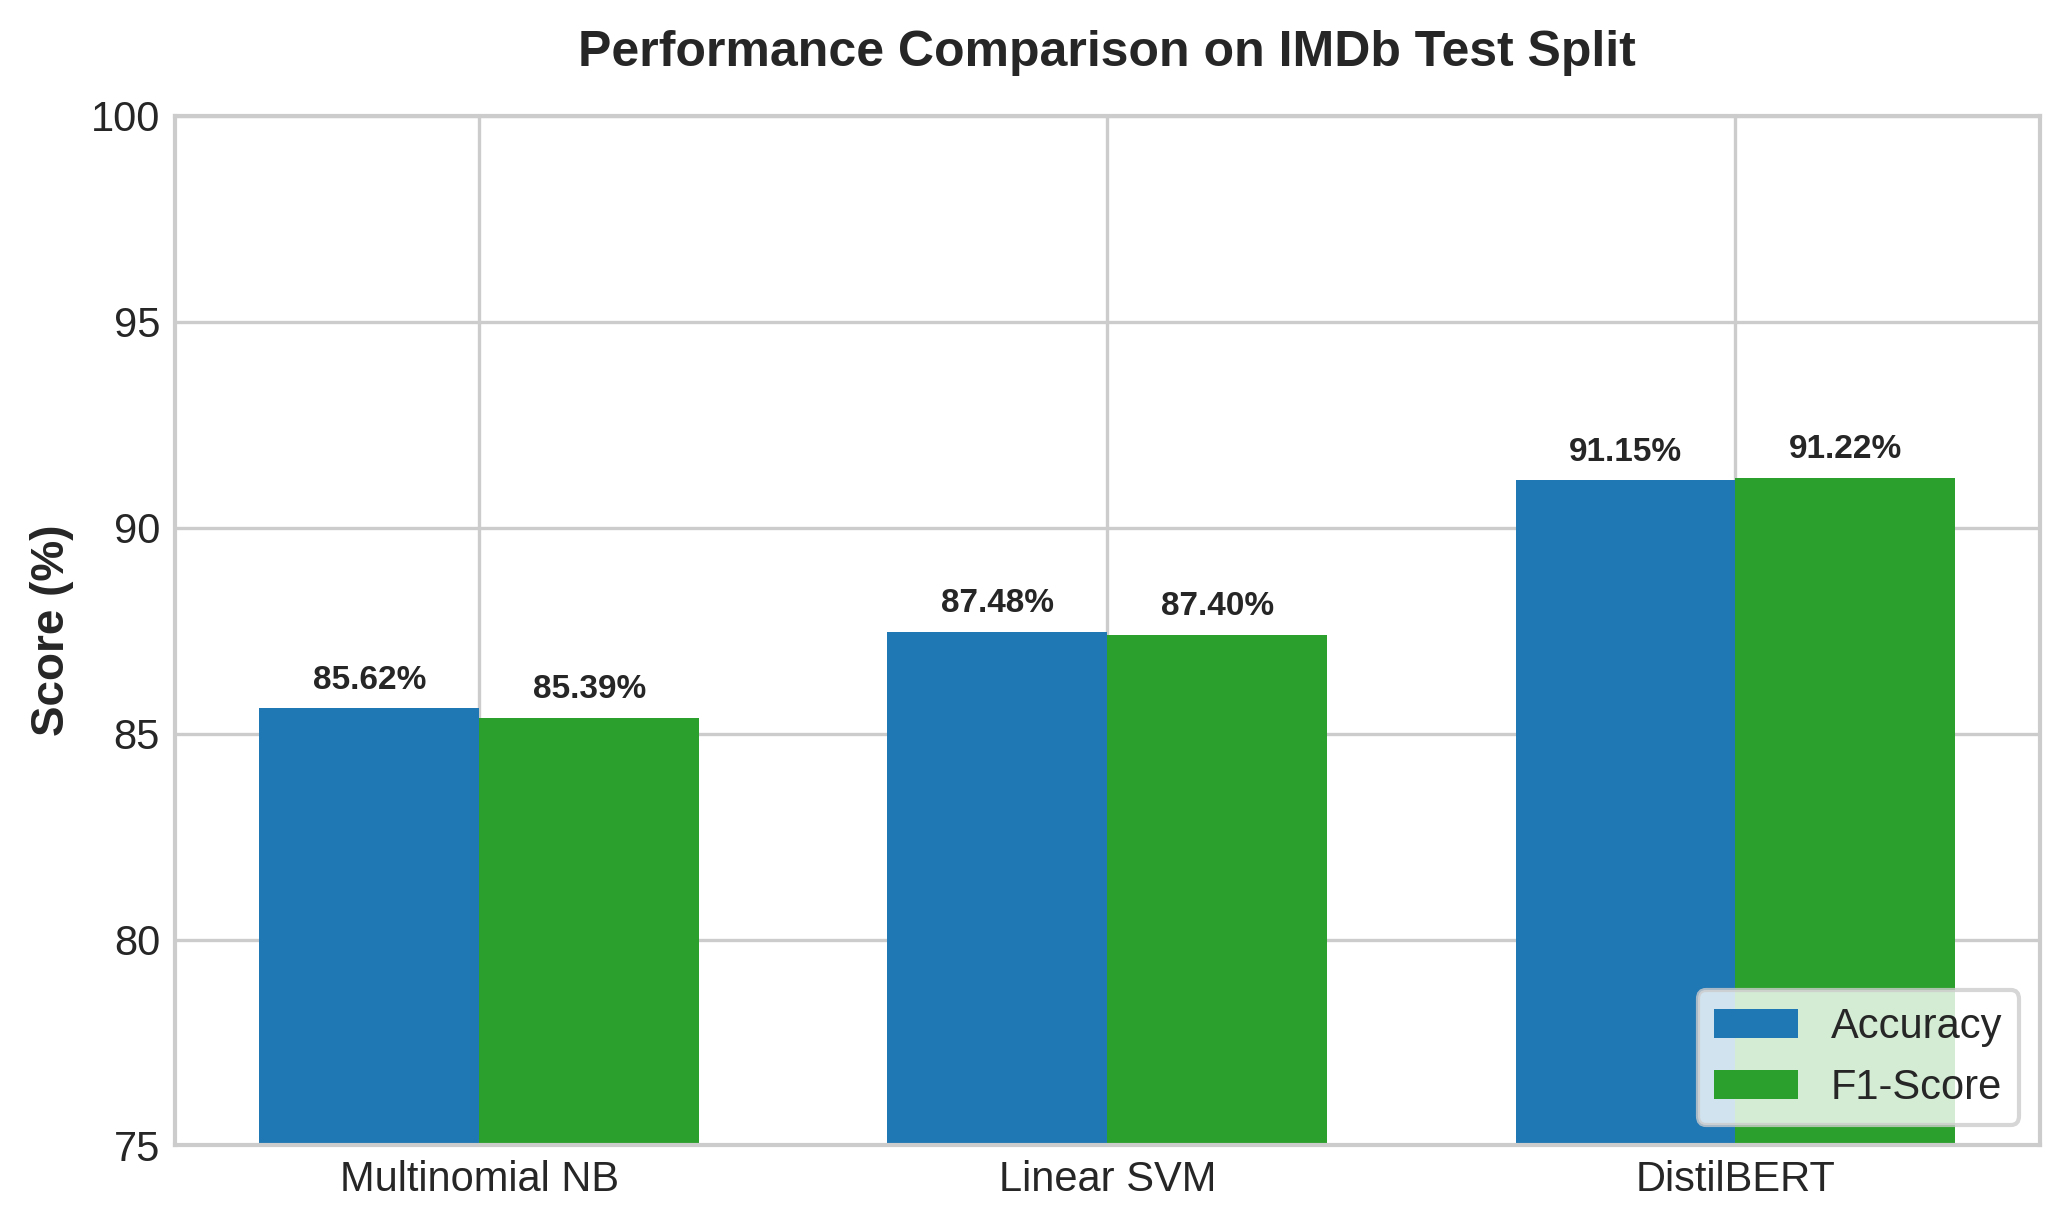

Figure exported successfully as 'figure01.png'.


In [9]:
# Cell 8: Plotting comparative benchmark and exporting figure01.png
import matplotlib.pyplot as plt
import pandas as pd

# Consolidate all experimental metrics into a clean DataFrame
final_metrics = {
    "Model": ["Multinomial NB", "Linear SVM", "DistilBERT"],
    "Accuracy (%)": [85.62, 87.48, 91.15],
    "F1-Score (%)": [85.39, 87.40, 91.22]
}

df_plot = pd.DataFrame(final_metrics)

# Configure plot aesthetics for academic paper standards
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=300)

x = range(len(df_plot))
width = 0.35

rects1 = ax.bar([p - width/2 for p in x], df_plot["Accuracy (%)"], width, label="Accuracy", color="#1f77b4")
rects2 = ax.bar([p + width/2 for p in x], df_plot["F1-Score (%)"], width, label="F1-Score", color="#2ca02c")

ax.set_ylabel("Score (%)", fontsize=11, fontweight="bold")
ax.set_title("Performance Comparison on IMDb Test Split", fontsize=12, fontweight="bold", pad=12)
ax.set_xticks(list(x))
ax.set_xticklabels(df_plot["Model"], fontsize=10)
ax.set_ylim(75, 100)
ax.legend(frameon=True, facecolor="white", loc="lower right")

# Annotate exact values atop bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f"{height:.2f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, fontweight="bold")

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig("figure01.png", dpi=300)
plt.show()

print("Figure exported successfully as 'figure01.png'.")